# 방향 개선 — 고조파 칸만 투표시키면 필요 SNR이 얼마나 내려가나 (실녹음)

> 2026-10-28 · 녹음 `T2_fpv`, `T_fpv` (Step8d T 측정) · 계산: [`doa/doa_stream.py`](../doa/doa_stream.py) (교차 스펙트럼, 채널 지연), [`doa/mask_phat.py`](../doa/mask_phat.py) (칸 고르기, 상관), [`harmonic/score.py`](../harmonic/score.py) (B0) · 커널: `Tools/.venv`
> 결론은 마지막 절에 **결론 후보**로만 적는다.

**질문:** 방향 계산(PHAT)이 300 ~ 3000 Hz의 221칸 전부로 투표하는 대신, **B0가 찾은 기본음의 배수 칸만** 투표하게 하면 방향의 필요 SNR(T)이 지금 24 dB(보수적)에서 얼마나 내려가나?

**배경:** Step8d 실측에서 방향은 SNR 12 ~ 20 dB 창의 상관 봉우리가 0.13 ~ 0.20으로 문턱 0.15 근처였다 (snr_T 7절). 사무실 세션의 합성 시험(`doa_mask_phat`, git `e589fb3`)에서는 고조파 칸만 쓰면 SNR 0 dB에서 유효율 33 % → 100 %였다. 이것을 실녹음으로 확인한다.

**방식 (기준선을 고정하고 하나씩 바꾼다)**

| 이름 | 투표하는 칸 | 방향을 내는 조건 |
|---|---|---|
| A 지금 방식 | 대역 안 221칸 전부 (doa.c와 같음) | 배경 대비 6 dB (소리 있음) |
| B 고조파 칸 | B0 기본음 f0의 배수 ±2칸 (300 ~ 3000 Hz 안) | 배경 대비 6 dB |
| C 고조파 칸 + B0 문 | B와 같음 | B0 점수 ≥ 13.1 (소리 있음 대신) |

**공통:** 배경 = 녹음 앞 조용한 구간 (보드가 쓴 7 dB 큰 배경 대신 **올바른 배경**). 관측 0.5 s, 이동 0.25 s, 블록 512, 채널 지연 보정, 유효 판정은 doa.h와 같다 (피크 ≥ 0.15, 닫힘 ≤ 0.3샘플, norm 0.5 ~ 1.3).
**성공** = 조건 통과 · 유효 · 높은 SNR 구간 방위 중앙값과 ±10° 안. SNR = ch1 300 ~ 3000 Hz (창 − 바닥) ÷ 바닥, 2 dB 칸 (snr_T와 같은 정의).
**한계:** 음원은 FPV 재생 (고정익 아님). 단일 음원, 배열 0° · 0.5 m 실내. B0의 f0가 틀리면 B·C의 칸도 틀린다.

In [1]:
import json, sys, warnings
import numpy as np, soundfile as sf
import matplotlib.pyplot as plt
from matplotlib import font_manager
_have = {f.name for f in font_manager.fontManager.ttflist}
plt.rcParams["font.family"] = next((f for f in ("Malgun Gothic", "AppleGothic", "NanumGothic") if f in _have), "sans-serif")
plt.rcParams["axes.unicode_minus"] = False
sys.path.insert(0, ".."); sys.path.insert(0, "../doa")
import doa_stream as ds, gcc_phat as g
DELAY = ds.channel_delays_us()                     # mask_phat를 불러오면 채널 지연을 0으로 바꾸므로 먼저 보관
import mask_phat as mp
ds.DELAY_US = DELAY
import harmonic.score as hs
FS = 12500; THR_B0 = 13.1; CANDS = [hs.candidates(40, 700)]
A = mp.args(); POS, D = ds.positions()
print("채널 지연 [us]:", np.round(DELAY, 1), "· 칸 간격", round(FS / mp.NFFT, 2), "Hz · 최대 지연", round(mp.MAX_LAG, 2), "샘플")

채널 지연 [us]: [  0.  -23.1   4.3] · 칸 간격 12.21 Hz · 최대 지연 3.55 샘플


## 1. 녹음 불러오기, 올바른 배경, 창마다 B0

배경 = 녹음 시작 3 s 뒤부터 소리 시작 2 s 전까지 (snr_T와 같은 소리 시작 찾기: 바닥보다 10 dB 이상이 3 s 이어지는 첫 시각).
방향 창(0.5 s)마다 그 창 가운데를 중심으로 한 1 s 창에서 B0 점수와 f0를 구한다.

In [2]:
def band_p(seg):
    w = np.hanning(len(seg)); X = np.fft.rfft((seg - seg.mean()) * w); f = np.fft.rfftfreq(len(seg), 1 / FS)
    m = (f >= 300) & (f < 3000); return 2 * np.sum(np.abs(X[m]) ** 2) / (len(seg) * np.sum(w ** 2))
REC = {}
for lab in ("T2_fpv", "T_fpv"):
    x, fs = sf.read(f"../dumps/stream/{lab}/seg_000.wav", dtype="float64"); x = (x - x.mean(0)).T   # [3, N]
    t = np.arange(0, x.shape[1] / FS - 1, 0.5)
    L = np.array([10 * np.log10(2 * band_p(x[0, int(s * FS):int(s * FS) + FS]) + 1e-30) for s in t])
    fl0 = np.median(L[(t > 3) & (t < 12)]); hi = (t > 12) & (L > fl0 + 10)
    on = t[np.argmax(np.convolve(hi, np.ones(6, int), "full")[5:][:len(t)] == 6)]
    bg = ds.cross_spectra(x[:, int(3 * FS):int((on - 2) * FS)], A.block, mp.NFFT)
    N1 = np.median([band_p(x[0, int(s * FS):int(s * FS) + 6250]) for s in np.arange(3, on - 2.5, 0.25)])
    s0 = np.arange(int((on - 1) * FS), x.shape[1] - 6250 - FS, int(0.25 * FS))
    b0 = []
    for s in s0:
        c = s + 3125 - FS // 2; w = x[0, max(c, 0):max(c, 0) + FS]
        b0.append(hs.score(w, CANDS)[0])
    b0 = np.array(b0)
    snr = np.array([10 * np.log10(max(band_p(x[0, s:s + 6250]) - N1, 1e-30) / N1) for s in s0])
    REC[lab] = dict(x=x, onset=on, bg=bg, N1=N1, s0=s0, score=b0[:, 0], f0=b0[:, 1], snr=snr)
    print(f"{lab}: 소리 시작 {on:.1f} s, 배경 {on - 5:.1f} s 분량, 방향 창 {len(s0)}개, B0 통과 {np.mean(b0[:, 0] >= THR_B0):.0%}")

T2_fpv: 소리 시작 32.0 s, 배경 27.0 s 분량, 방향 창 2650개, B0 통과 67%


T_fpv: 소리 시작 24.5 s, 배경 19.5 s 분량, 방향 창 2613개, B0 통과 93%


## 2. 창 하나 손으로 따라가기 — 같은 창, 칸만 다르게

SNR 약 10 dB 창 하나에서 A(221칸)와 B(고조파 칸)의 상관 곡선을 겹쳐 본다.
**예상:** 봉우리 위치(지연)는 비슷하고, 높이가 다르다. 봉우리 높이 = 투표한 칸 중 그 지연에 동의한 비율이라, 잡음 칸을 빼면 높아진다.

창 360.50 ~ 361.00 s, ch1 SNR 10.0 dB, B0 점수 19.0 · f0 268 Hz
  A 221칸   : 칸 221, 봉우리 [0.54, 0.51, 0.47], 닫힘 -0.14, norm 0.80, 방위  -10.4°, 유효 True
  B 고조파 칸  : 칸  50, 봉우리 [0.59, 0.54, 0.49], 닫힘 -0.27, norm 0.73, 방위  -10.6°, 유효 True


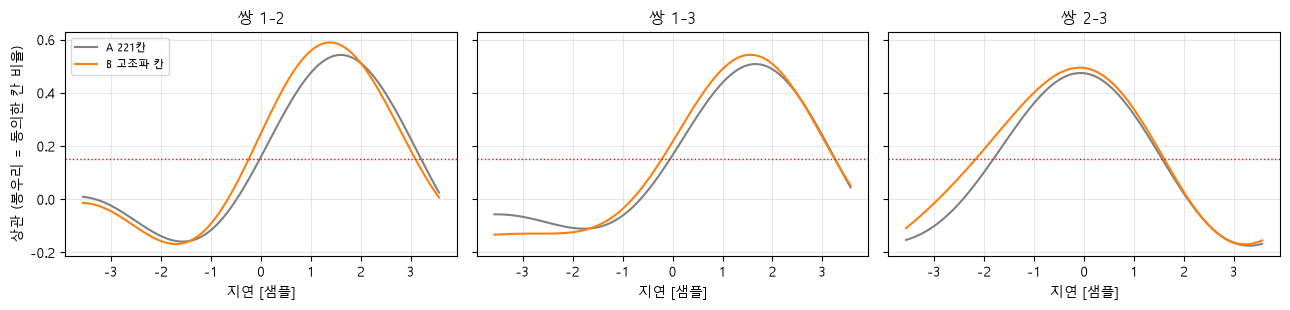

In [3]:
def run_window(x, s, bg, method, f0):
    S = ds.cross_spectra(x[:, s:s + 6250], A.block, mp.NFFT)
    snr3 = 10 * np.log10(sum(S[3 + c][mp.FREQ_IN].sum() for c in range(3)).real / sum(bg[3 + c][mp.FREQ_IN].sum() for c in range(3)).real)
    R = [S[k] - bg[k] for k in range(3)]
    mask = mp.make_mask(S, "full" if method == "A" else "oracle", f0)
    cur = [mp.phat_curve(Rk, mask) for Rk in R]
    tau = []
    for k, (i, j) in enumerate(g.PAIRS): tau.append(cur[k][2] - (DELAY[j] - DELAY[i]) * 1e-6 * FS)
    ang, norm = g.tdoa_to_angle(tau, FS, POS)
    r = dict(tau=tau, peak=[c[3] for c in cur], angle=ang, norm=norm, closure=tau[0] + tau[2] - tau[1], nbins=int(mask.sum()), snr3=snr3)
    r["valid"] = ds.is_valid(r, A); r["curves"] = cur
    return r
mp.FREQ_IN = (mp.FREQ >= 300) & (mp.FREQ <= 3000)
R = REC["T2_fpv"]; i = int(np.argmin(np.abs(R["snr"] - 10) + 100 * (R["score"] < THR_B0)))
s = R["s0"][i]; f0 = R["f0"][i]
ra, rb = run_window(R["x"], s, R["bg"], "A", f0), run_window(R["x"], s, R["bg"], "B", f0)
print(f"창 {s / FS:.2f} ~ {s / FS + 0.5:.2f} s, ch1 SNR {R['snr'][i]:.1f} dB, B0 점수 {R['score'][i]:.1f} · f0 {f0:.0f} Hz")
for nm, r in (("A 221칸", ra), ("B 고조파 칸", rb)):
    print(f"  {nm:9s}: 칸 {r['nbins']:3d}, 봉우리 {np.round(r['peak'], 2).tolist()}, 닫힘 {r['closure']:+.2f}, norm {r['norm']:.2f}, 방위 {r['angle']:6.1f}°, 유효 {r['valid']}")
fig, ax = plt.subplots(1, 3, figsize=(13, 3.2), sharey=True)
for k, a in enumerate(ax):
    for nm, r, c in (("A 221칸", ra, "0.5"), ("B 고조파 칸", rb, "C1")):
        lags, cc = r["curves"][k][0], r["curves"][k][1]; a.plot(lags, cc, color=c, label=nm)
    a.axhline(0.15, color="r", ls=":", lw=1); a.set_title(f"쌍 {g.PAIRS[k][0] + 1}-{g.PAIRS[k][1] + 1}"); a.set_xlabel("지연 [샘플]"); a.grid(alpha=.3)
ax[0].set_ylabel("상관 (봉우리 = 동의한 칸 비율)"); ax[0].legend(fontsize=8); plt.tight_layout(); plt.show()

## 3. 세 방식 전체 실행

방향 창마다 A·B·C를 계산한다 (B·C는 B0가 준 f0를 쓴다. B0 점수가 문턱 밑이면 B는 f0가 믿을 만하지 않아도 그대로 쓰고, C는 방향을 내지 않는다). 몇 분 걸린다.

In [4]:
OUT = {}
for lab, R in REC.items():
    ra = [run_window(R["x"], s, R["bg"], "A", f) for s, f in zip(R["s0"], R["f0"])]
    rb = [run_window(R["x"], s, R["bg"], "B", f) for s, f in zip(R["s0"], R["f0"])]
    OUT[lab] = dict(A=ra, B=rb)
    print(f"{lab}: {len(ra)}창 완료")

T2_fpv: 2650창 완료


T_fpv: 2613창 완료


In [5]:
def success(lab, method):
    R = REC[lab]; rs = OUT[lab]["B" if method in ("B", "C") else "A"]
    ang = np.array([r["angle"] for r in rs]); val = np.array([r["valid"] for r in rs]); snr3 = np.array([r["snr3"] for r in rs])
    gate = (R["score"] >= THR_B0) if method == "C" else (snr3 >= 6.0)
    hi = val & gate & (R["snr"] >= 25)
    ref = np.degrees(np.angle(np.mean(np.exp(1j * np.radians(ang[hi])))))
    err = np.abs((ang - ref + 180) % 360 - 180)
    return gate & val & (err <= 10), gate & val & (err > 10), ref
BINS = np.arange(-6, 46, 2)
def curve(snr, ok):
    c, r, n = [], [], []
    for lo in BINS[:-1]:
        m = (snr >= lo) & (snr < lo + 2)
        if m.sum() >= 10: c.append(lo + 1); r.append(ok[m].mean()); n.append(m.sum())
    return np.array(c), np.array(r), np.array(n)
def cross(c, r, p):
    for i in range(len(c) - 1, 0, -1):
        if r[i] >= p > r[i - 1]: return c[i - 1] + (p - r[i - 1]) / (r[i] - r[i - 1]) * (c[i] - c[i - 1])
    return np.nan
def tstr(c, r, p):
    v = cross(c, r, p)
    if np.isfinite(v): return f"{v:.1f}"
    return f"< {c[0] - 1:.0f}" if np.all(r >= p) else (f"> {c[-1] + 1:.0f}" if np.all(r < p) else "?")

## 4. 성공률 곡선과 T

▶ **예측 지점 (T1)** — 아래 곡선을 보기 전에 대화에서 예측한다.

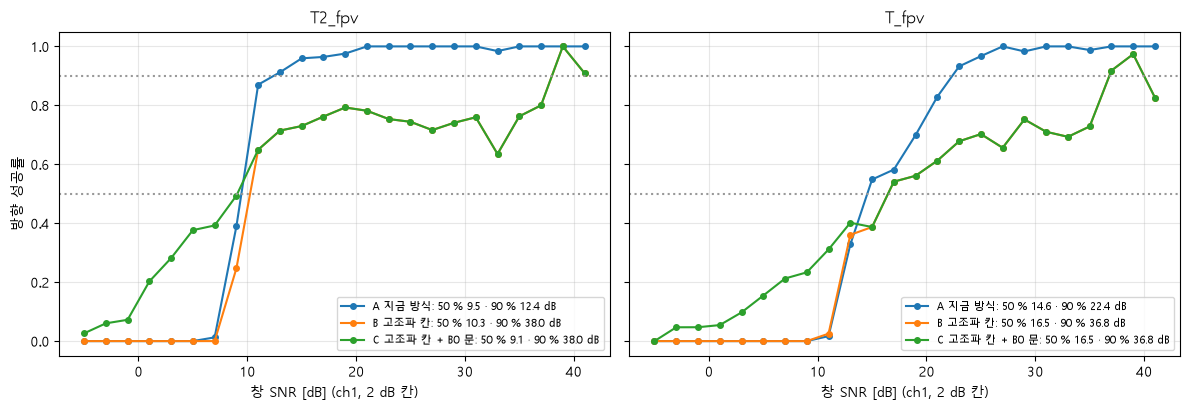

T2_fpv  A 지금 방식         : T50    9.5 · T90   12.4 dB · 낸 방향 중 오답(> 10°) 0/1131 = 0.0%
T2_fpv  B 고조파 칸         : T50   10.3 · T90   38.0 dB · 낸 방향 중 오답(> 10°) 17/881 = 1.9%
T2_fpv  C 고조파 칸 + B0 문  : T50    9.1 · T90   38.0 dB · 낸 방향 중 오답(> 10°) 53/1048 = 5.1%
T_fpv   A 지금 방식         : T50   14.6 · T90   22.4 dB · 낸 방향 중 오답(> 10°) 1/1242 = 0.1%
T_fpv   B 고조파 칸         : T50   16.5 · T90   36.8 dB · 낸 방향 중 오답(> 10°) 96/1051 = 9.1%
T_fpv   C 고조파 칸 + B0 문  : T50   16.5 · T90   36.8 dB · 낸 방향 중 오답(> 10°) 142/1228 = 11.6%


In [6]:
NAME = {"A": "A 지금 방식", "B": "B 고조파 칸", "C": "C 고조파 칸 + B0 문"}
RES = {}
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
for a, lab in zip(ax, REC):
    for m in "ABC":
        ok, wrong, ref = success(lab, m); c, r, n = curve(REC[lab]["snr"], ok)
        RES[(lab, m)] = (c, r, n, wrong, ok)
        a.plot(c, r, "o-", ms=4, label=f"{NAME[m]}: 50 % {tstr(c, r, .5)} · 90 % {tstr(c, r, .9)} dB")
    a.axhline(.5, color="0.6", ls=":"); a.axhline(.9, color="0.6", ls=":")
    a.set_title(lab); a.set_xlabel("창 SNR [dB] (ch1, 2 dB 칸)"); a.grid(alpha=.3); a.legend(fontsize=8)
ax[0].set_ylabel("방향 성공률"); plt.tight_layout(); plt.show()
for (lab, m), (c, r, n, wrong, ok) in RES.items():
    out = ok | wrong
    print(f"{lab:7s} {NAME[m]:16s}: T50 {tstr(c, r, .5):>6s} · T90 {tstr(c, r, .9):>6s} dB · 낸 방향 중 오답(> 10°) {wrong.sum()}/{out.sum()} = {wrong.sum() / max(out.sum(), 1):.1%}")

## 5. 발견

- 아래 셀: 방향을 낸 창 중 오답(정답과 10° 넘게 다름)이 어느 SNR에서 생기나. 칸을 줄이면 피크 문턱이 거르는 힘이 약해진다는 합성 시험의 경고(9절)를 실녹음에서 본다.

In [7]:
for (lab, m), (c, r, n, wrong, ok) in RES.items():
    if m == "A": continue
    snr = REC[lab]["snr"]; out = []
    for lo in (-6, 0, 6, 12, 18):
        k = (snr >= lo) & (snr < lo + 6); d = (ok | wrong) & k
        out.append(f"{lo:3d} ~ {lo + 6:2d} dB: {wrong[k].sum()}/{d.sum()}")
    print(f"{lab:7s} {NAME[m]:16s} 오답/낸 방향 — " + " · ".join(out))

T2_fpv  B 고조파 칸          오답/낸 방향 —  -6 ~  0 dB: 0/0 ·   0 ~  6 dB: 0/0 ·   6 ~ 12 dB: 5/74 ·  12 ~ 18 dB: 5/188 ·  18 ~ 24 dB: 1/189
T2_fpv  C 고조파 칸 + B0 문   오답/낸 방향 —  -6 ~  0 dB: 12/25 ·   0 ~  6 dB: 14/82 ·   6 ~ 12 dB: 14/133 ·  12 ~ 18 dB: 5/188 ·  18 ~ 24 dB: 1/189
T_fpv   B 고조파 칸          오답/낸 방향 —  -6 ~  0 dB: 0/0 ·   0 ~  6 dB: 0/0 ·   6 ~ 12 dB: 3/6 ·  12 ~ 18 dB: 25/183 ·  18 ~ 24 dB: 25/253
T_fpv   C 고조파 칸 + B0 문   오답/낸 방향 —  -6 ~  0 dB: 0/7 ·   0 ~  6 dB: 16/49 ·   6 ~ 12 dB: 32/121 ·  12 ~ 18 dB: 25/188 ·  18 ~ 24 dB: 25/253


## 6. 결론 후보 (사용자 확인 전)

지금 보수적 값(T90 24.3 dB, Step8d) 대비 거리 배수 = 10^((24.3 − T) ÷ 20).

In [8]:
for (lab, m), (c, r, n, wrong, ok) in RES.items():
    t90 = cross(c, r, .9); f = (f"×{10 ** ((24.3 - t90) / 20):.1f}" if np.isfinite(t90) else "-")
    out = ok | wrong
    print(f"{lab:7s} {NAME[m]:16s}: T50 {tstr(c, r, .5):>6s} dB · T90 {tstr(c, r, .9):>6s} dB (방향 거리 {f}) · 오답률 {wrong.sum() / max(out.sum(), 1):.1%}  (근거 4·5절)")
print()
print("아직 모르는 것: 고정익 음원에서도 같은가, 두 음원이 섞일 때 f0가 다른 음원을 가리키면, 보드(MCU)에서 B0 f0를 방향 계산에 넘기는 비용")

T2_fpv  A 지금 방식         : T50    9.5 dB · T90   12.4 dB (방향 거리 ×3.9) · 오답률 0.0%  (근거 4·5절)
T2_fpv  B 고조파 칸         : T50   10.3 dB · T90   38.0 dB (방향 거리 ×0.2) · 오답률 1.9%  (근거 4·5절)
T2_fpv  C 고조파 칸 + B0 문  : T50    9.1 dB · T90   38.0 dB (방향 거리 ×0.2) · 오답률 5.1%  (근거 4·5절)
T_fpv   A 지금 방식         : T50   14.6 dB · T90   22.4 dB (방향 거리 ×1.2) · 오답률 0.1%  (근거 4·5절)
T_fpv   B 고조파 칸         : T50   16.5 dB · T90   36.8 dB (방향 거리 ×0.2) · 오답률 9.1%  (근거 4·5절)
T_fpv   C 고조파 칸 + B0 문  : T50   16.5 dB · T90   36.8 dB (방향 거리 ×0.2) · 오답률 11.6%  (근거 4·5절)

아직 모르는 것: 고정익 음원에서도 같은가, 두 음원이 섞일 때 f0가 다른 음원을 가리키면, 보드(MCU)에서 B0 f0를 방향 계산에 넘기는 비용
